In [1]:
import sys
from pathlib import Path

# Cherche le dossier racine du projet (BDS_Fault_Detection) pour faire les imports depuis Sources/
dossier = Path().resolve()
for parent in (dossier, *dossier.parents):
    if "BDS_Fault_Detection" in parent.name:
        RACINE = parent
sys.path.insert(0, str(RACINE))

# Importation des fonctions du projet (dossier Sources/). Attention de l'ordre d'importation  !
from Sources import data, config, features, models

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import roc_auc_score, confusion_matrix


I0000 00:00:1795603005.844792   54808 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
# === Chargement du modèle entrainé === #
import keras
Fitted_Model = keras.models.load_model(RACINE / "Sources" / "Fitted_models" / "DAE_fitted.keras")

In [3]:
# DUREE_FENETRE = config.DUREE_FENETRE

# def construire_fenetres_brutes_test(nom, canal="DE", duree=DUREE_FENETRE/2, recouvrement=0.5):
#     SB, lignes = [], []
#     s = data.charger(nom, canaux=(canal,))
#     for i, val in enumerate(features.fenetrer(s[canal], 12000, duree=duree, recouvrement=recouvrement)):
#         SB.append(val)
#     return np.array(SB, dtype=np.float32)#, pd.DataFrame(lignes)

# def score_mse(modele, X):
#     Xr = modele.predict(X[..., None], verbose=0)[..., 0]
#     return ((X - Xr) ** 2).mean(axis=1)

# def Tester_signal(modele, input):
#     score = score_mse(modele, input)
#     seuil = 0.0083                  # === Seuil définit lors du fit sur les données train === #
#     Nb_Defaut = (score > seuil).sum()
#     Nb_Sain = (score < seuil).sum()
#     Erreur_moyenne = score.mean()
#     EstDefautPourcent = Nb_Defaut/(Nb_Sain+Nb_Defaut)
#     print(f"Pourcentage de chance d'être un défaut : {EstDefautPourcent*100:.2f}%")
#     plt.plot(score, label="Signal testé")
#     plt.axhline(seuil, color="black", ls="--", lw=1, label="seuil d'alarme")
#     plt.title("Score d'anomalie au cours du temps")
#     plt.xlabel("fenêtre du signal"); plt.ylabel("MSE de reconstruction")
#     plt.xlim(0, Nb_Sain+Nb_Defaut)
#     plt.ylim(0, 1)
#     plt.legend(); plt.show()
#     return ()

In [ ]:
def construire_fenetres_brutes_test(nom, canal="DE", duree=0.17067, recouvrement=0.5):
    s = data.charger(nom, canaux=(canal,))
    fenetres = features.fenetrer(s[canal], s["fs"], duree=duree, recouvrement=recouvrement)
    return np.array(fenetres, dtype=np.float32)

def score_mse(modele, X):
    Xr = modele.predict(X[..., None], verbose=0)[..., 0]
    return ((X - Xr) ** 2).mean(axis=1)

def Tester_signal(modele, input, seuil):
    score = score_mse(modele, input)
    Nb_Defaut = (score > seuil).sum()
    Nb_Sain = (score < seuil).sum()
    print(f"Pourcentage de chance d'être un défaut : {Nb_Defaut/(Nb_Sain+Nb_Defaut)*100:.2f}%")
    plt.plot(score, label="Signal testé")
    plt.axhline(seuil, color="black", ls="--", lw=1, label="seuil d'alarme")
    plt.title("Score d'anomalie au cours du temps")
    plt.xlabel("fenêtre du signal"); plt.ylabel("MSE de reconstruction")
    plt.legend(); plt.show()

Pourcentage de chance d'être un défaut : 100.00%


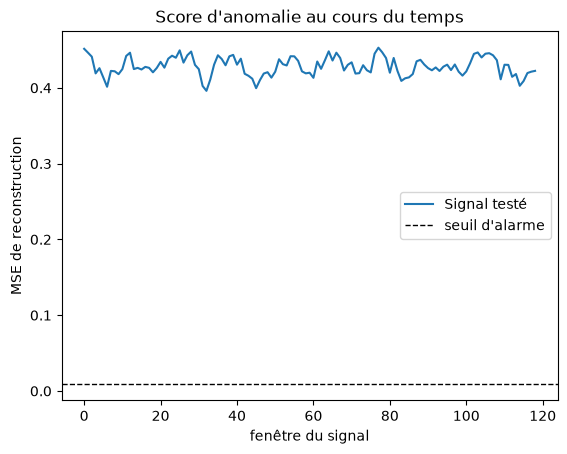

In [9]:
import joblib
pack = joblib.load(RACINE / "Sources" / "Fitted_models" / "DAE_params.joblib")
seuil, taille = pack["seuil"], pack["taille_fenetre"]

# Normal_L0, 12kDE_B021_L1, 12kDE_IR007_L3, 12kFE_IR007_L0, 12kFE_OR007at12_L0
SB_test = construire_fenetres_brutes_test("12kDE_IR007_L3", canal="FE")

assert SB_test.shape[1] == taille, \
    f"fenêtres de {SB_test.shape[1]} éch., modèle entraîné sur {taille} (vérifier duree et fs)"
SB_test_norm = features.standardiser_par_fenetre(SB_test)   # même règle qu'à l'entraînement, AUCUN fit

Tester_signal(Fitted_Model, SB_test_norm, seuil)